In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ba2lll/ubl-price/UBL.csv


### Imports, load and clean

In [2]:
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow.keras import Sequential, layers, callbacks
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score

df = pd.read_csv("/kaggle/input/datasets/ba2lll/ubl-price/UBL.csv")
df.columns = df.columns.str.strip().str.upper()
df["DATE"] = pd.to_datetime(df["DATE"])
df = df[df["DATE"] >= "2021-01-01"].drop_duplicates()
ok = ((df[["OPEN","HIGH","LOW","CLOSE"]] > 0).all(axis=1) & (df["VOLUME"] >= 0)
      & (df["HIGH"] >= df[["OPEN","CLOSE","LOW"]].max(axis=1))
      & (df["LOW"] <= df[["OPEN","CLOSE","HIGH"]].min(axis=1)))
df = df[ok].sort_values("DATE")
df = df[(df.DATE >= "2021-09-30") & (df.DATE <= "2026-06-30")].reset_index(drop=True)
assert df.DATE.is_unique
print(len(df), df.DATE.min(), df.DATE.max())

1176 2021-09-30 00:00:00 2026-06-30 00:00:00


In [3]:
df.head()

,DATE,OPEN,HIGH,LOW,CLOSE,VOLUME,CHANGE
0,2021-09-30,117.33,119.00,116.00,118.56,2127141,1.41
1,2021-10-01,118.00,119.45,117.05,117.83,506091,-0.73
2,2021-10-04,115.15,118.95,115.15,118.37,756631,0.54
3,2021-10-05,118.50,120.68,117.50,120.01,1526238,1.64
4,2021-10-06,120.90,122.49,119.00,121.92,1925997,1.91


### Features and target

In [4]:
df["ret"] = np.log(df.CLOSE).diff()
df["hl_range"] = (df.HIGH - df.LOW) / df.CLOSE
df["oc_change"] = (df.CLOSE - df.OPEN) / df.OPEN
df["log_vol"] = np.log1p(df.VOLUME)
df["ma5_ratio"] = df.CLOSE / df.CLOSE.rolling(5).mean() - 1
df["ma20_ratio"] = df.CLOSE / df.CLOSE.rolling(20).mean() - 1
df["vol10"] = df.ret.rolling(10).std()
df["target_ret"] = df.ret.shift(-1)          # next-day log return
df["tdate"] = df.DATE.shift(-1)              # date being predicted
df["next_close"] = df.CLOSE.shift(-1)
df = df.dropna().reset_index(drop=True)

### Windows, split & scaling

In [5]:
feats = ["ret","hl_range","oc_change","log_vol","ma5_ratio","ma20_ratio","vol10"]
W = 30
X, y, td, pc, nc = [], [], [], [], []
for i in range(W-1, len(df)):
    X.append(df[feats].iloc[i-W+1:i+1].values)
    y.append(df.target_ret.iloc[i]); td.append(df.tdate.iloc[i])
    pc.append(df.CLOSE.iloc[i]); nc.append(df.next_close.iloc[i])
X, y, pc, nc = map(np.array, (X, y, pc, nc))
td = pd.to_datetime(td)

tr = np.asarray(td <= pd.Timestamp("2025-01-23"))
va = np.asarray((td > pd.Timestamp("2025-01-23")) & (td <= pd.Timestamp("2025-10-10")))
te = np.asarray(td > pd.Timestamp("2025-10-10"))
print(tr.sum(), va.sum(), te.sum())

sx = StandardScaler().fit(X[tr].reshape(-1, len(feats)))      # fit on train only
sc = lambda a: sx.transform(a.reshape(-1, len(feats))).reshape(a.shape)
Xtr, Xva, Xte = sc(X[tr]), sc(X[va]), sc(X[te])
sy = StandardScaler().fit(y[tr].reshape(-1,1))
ytr, yva = sy.transform(y[tr].reshape(-1,1)), sy.transform(y[va].reshape(-1,1))

774 176 177


### Metrics and naive baseline

In [6]:
def report(name, actual, pred, prev):
    mape = np.mean(np.abs((actual-pred)/actual))*100
    da = np.mean(np.sign(actual-prev) == np.sign(pred-prev))*100
    print(f"{name}: MAE {MAE(actual,pred):.2f} RMSE {np.sqrt(MSE(actual,pred)):.2f} "
          f"MAPE {mape:.2f}% R2 {r2_score(actual,pred):.3f} DirAcc {da:.1f}%")

report("Naive (yesterday's close)", nc[te], pc[te], pc[te])

Naive (yesterday's close): MAE 7.86 RMSE 11.10 MAPE 1.94% R2 0.942 DirAcc 0.0%


### MLP baseline

In [7]:
tf.random.set_seed(42); np.random.seed(42)
Xtr_f, Xva_f, Xte_f = [a.reshape(len(a), -1) for a in (Xtr, Xva, Xte)]

mlp = Sequential([
    layers.Input((Xtr_f.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)])
mlp.compile("adam", "mse")
mlp.fit(Xtr_f, ytr, validation_data=(Xva_f, yva), epochs=100, batch_size=32,
        callbacks=[callbacks.EarlyStopping(patience=15, restore_best_weights=True)])

pred_ret = sy.inverse_transform(mlp.predict(Xte_f)).ravel()
report("MLP (price)", nc[te], pc[te] * np.exp(pred_ret), pc[te])

I0000 00:00:1792617122.573299      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792617122.577225      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/100
24/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.9322 

I0000 00:00:1792617127.290838      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 67ms/step - loss: 1.6480 - val_loss: 12.1446
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1.1122 - val_loss: 12.4997
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9432 - val_loss: 12.4168
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8423 - val_loss: 12.8459
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7475 - val_loss: 12.7354
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7346 - val_loss: 13.3446
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6677 - val_loss: 13.2898
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.6581 - val_loss: 13.1890
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5622 - val_loss: 13.1164
Epoch 10/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5598 - val_loss: 13.2770
Epoch 11/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5281 - val_loss: 13.5152
Epoch 12/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5

### LSTM

In [8]:
tf.random.set_seed(42); np.random.seed(42)
lstm = Sequential([
    layers.Input((W, len(feats))),
    layers.LSTM(64),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)])
lstm.compile("adam", "mse")
lstm.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=100, batch_size=32,
         callbacks=[callbacks.EarlyStopping(patience=15, restore_best_weights=True)])

pred_ret = sy.inverse_transform(lstm.predict(Xte)).ravel()
pred_close = pc[te] * np.exp(pred_ret)
report("LSTM", nc[te], pred_close, pc[te])

pd.DataFrame({"DATE": td[te], "Actual Close": nc[te], "Predicted Close": pred_close}
            ).to_csv("lstm_price_predictions.csv", index=False)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 1.0293 - val_loss: 10.6803
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9927 - val_loss: 10.6944
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9759 - val_loss: 10.7097
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9757 - val_loss: 10.6857
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9687 - val_loss: 10.7476
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.9604 - val_loss: 10.7364
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9534 - val_loss: 10.7693
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9386 - val_loss: 10.7913
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9383 - val_loss: 10.8172
Epoch 10/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9272 - val_loss: 10.8829
Epoch 11/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.9108 - val_loss: 10.8927
Epoch 12/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s

### Validation scores & plots

In [9]:
pc_v, nc_v = pc[va], nc[va]
report("Naive  [val]", nc_v, pc_v, pc_v)
r = sy.inverse_transform(mlp.predict(Xva_f)).ravel()
report("MLP    [val]", nc_v, pc_v*np.exp(r), pc_v)
r = sy.inverse_transform(lstm.predict(Xva)).ravel()
report("LSTM   [val]", nc_v, pc_v*np.exp(r), pc_v)

Naive  [val]: MAE 7.72 RMSE 22.32 MAPE 2.04% R2 0.881 DirAcc 0.0%
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
MLP    [val]: MAE 10.84 RMSE 23.30 MAPE 2.87% R2 0.870 DirAcc 52.3%
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
LSTM   [val]: MAE 7.68 RMSE 22.30 MAPE 2.04% R2 0.881 DirAcc 50.0%


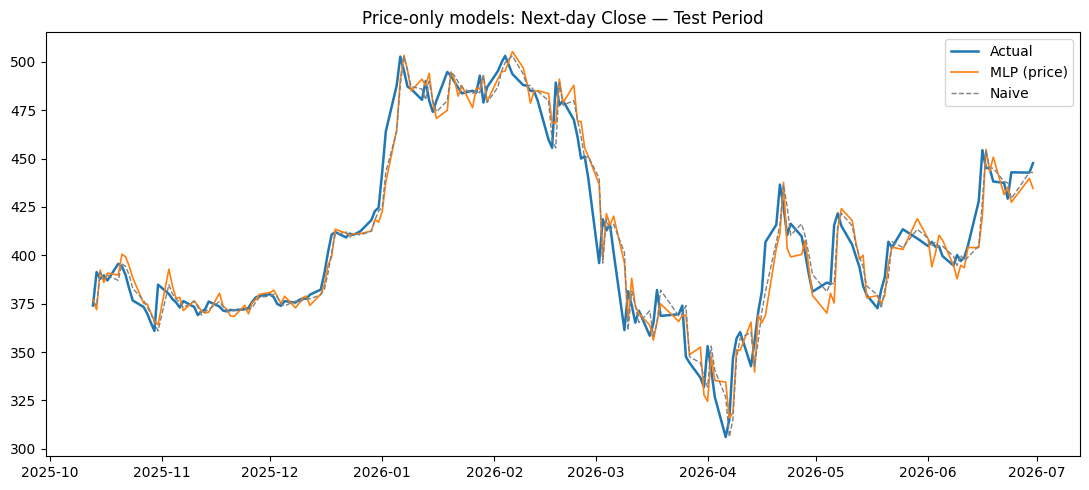

In [10]:
import matplotlib.pyplot as plt
p_mlp  = pc[te] * np.exp(sy.inverse_transform(mlp.predict(Xte_f, verbose=0)).ravel())
# p_lstm = pc[te] * np.exp(sy.inverse_transform(lstm.predict(Xte, verbose=0)).ravel())

plt.figure(figsize=(11, 5))
plt.plot(td[te], nc[te], label="Actual", color="#1f77b4", lw=1.8)
plt.plot(td[te], p_mlp, label="MLP (price)", color="#ff7f0e", lw=1.2)
# plt.plot(td[te], p_lstm, label="LSTM (price)", color="#2ca02c", lw=1.2)
plt.plot(td[te], pc[te], label="Naive", color="gray", lw=1, ls="--")
plt.title("Price-only models: Next-day Close — Test Period")
plt.legend(); plt.tight_layout()
plt.savefig("actual_vs_pred_v2.png", dpi=200); plt.show()

### Window size search

In [11]:
def run_window(W, units=64):
    Xw, yw, tdw, pcw, ncw = [], [], [], [], []
    for i in range(W-1, len(df)):
        Xw.append(df[feats].iloc[i-W+1:i+1].values)
        yw.append(df.target_ret.iloc[i]); tdw.append(df.tdate.iloc[i])
        pcw.append(df.CLOSE.iloc[i]); ncw.append(df.next_close.iloc[i])
    Xw, yw, pcw, ncw = map(np.array, (Xw, yw, pcw, ncw))
    tdw = pd.to_datetime(tdw)
    trw = np.asarray(tdw <= pd.Timestamp("2025-01-23"))
    vaw = np.asarray((tdw > pd.Timestamp("2025-01-23")) & (tdw <= pd.Timestamp("2025-10-10")))
    sxw = StandardScaler().fit(Xw[trw].reshape(-1, len(feats)))
    scw = lambda a: sxw.transform(a.reshape(-1, len(feats))).reshape(a.shape)
    syw = StandardScaler().fit(yw[trw].reshape(-1,1))
    tf.random.set_seed(42); np.random.seed(42)
    m = Sequential([layers.Input((W, len(feats))), layers.LSTM(units),
                    layers.Dropout(0.2), layers.Dense(32, activation="relu"), layers.Dense(1)])
    m.compile("adam", "mse")
    m.fit(scw(Xw[trw]), syw.transform(yw[trw].reshape(-1,1)),
          validation_data=(scw(Xw[vaw]), syw.transform(yw[vaw].reshape(-1,1))),
          epochs=100, batch_size=32, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=15, restore_best_weights=True)])
    r = syw.inverse_transform(m.predict(scw(Xw[vaw]), verbose=0)).ravel()
    pred = pcw[vaw] * np.exp(r)
    return np.mean(np.abs((ncw[vaw]-pred)/ncw[vaw]))*100, np.mean(np.abs((ncw[vaw]-pcw[vaw])/ncw[vaw]))*100

for W_try in [10, 20, 30, 60]:
    lstm_mape, naive_mape = run_window(W_try)
    print(f"W={W_try}: LSTM val MAPE {lstm_mape:.2f}% | naive {naive_mape:.2f}%")

W=10: LSTM val MAPE 2.33% | naive 2.04%
W=20: LSTM val MAPE 2.04% | naive 2.04%
W=30: LSTM val MAPE 2.04% | naive 2.04%
W=60: LSTM val MAPE 2.03% | naive 2.04%


### Results

In [12]:
def metrics(actual, pred, prev):
    return {
        "MAE": MAE(actual, pred),
        "RMSE": np.sqrt(MSE(actual, pred)),
        "MAPE": np.mean(np.abs((actual - pred) / actual)) * 100,
        "R²": r2_score(actual, pred),
        "Dir. acc.": np.mean(np.sign(actual - prev) == np.sign(pred - prev)) * 100,
    }

splits = {"Train": tr, "Validation": va, "Test": te}
inputs = {"MLP": (Xtr_f, Xva_f, Xte_f)}
models = {"MLP": mlp}

rows = []
# Naive baseline (directional accuracy isn't meaningful for it)
for sname, idx in splits.items():
    m = metrics(nc[idx], pc[idx], pc[idx]); m["Dir. acc."] = np.nan
    rows.append({"Model": "Naive", "Split": sname, **m})
# MLP and LSTM: predict return, convert back to close price
for mname, model in models.items():
    for k, (sname, idx) in enumerate(splits.items()):
        r = sy.inverse_transform(model.predict(inputs[mname][k], verbose=0)).ravel()
        rows.append({"Model": mname, "Split": sname,
                     **metrics(nc[idx], pc[idx] * np.exp(r), pc[idx])})

res = pd.DataFrame(rows)
res.to_csv("price_results_table.csv", index=False)

# Format like her slide
fmt = res.copy()
for c in ["MAE", "RMSE"]: fmt[c] = fmt[c].map("{:.2f}".format)
fmt["MAPE"] = fmt["MAPE"].map("{:.2f}%".format)
fmt["R²"] = fmt["R²"].map("{:.3f}".format)
fmt["Dir. acc."] = fmt["Dir. acc."].map(lambda v: "n/a" if pd.isna(v) else f"{v:.1f}%")
fmt

,Model,Split,MAE,RMSE,MAPE,R²,Dir. acc.
0,Naive,Train,2.09,3.36,1.18%,0.998,n/a
1,Naive,Validation,7.72,22.32,2.04%,0.881,n/a
2,Naive,Test,7.86,11.10,1.94%,0.942,n/a
3,MLP,Train,2.21,3.31,1.28%,0.998,52.8%
4,MLP,Validation,10.84,23.30,2.87%,0.870,52.3%
5,MLP,Test,8.89,12.12,2.19%,0.931,45.2%


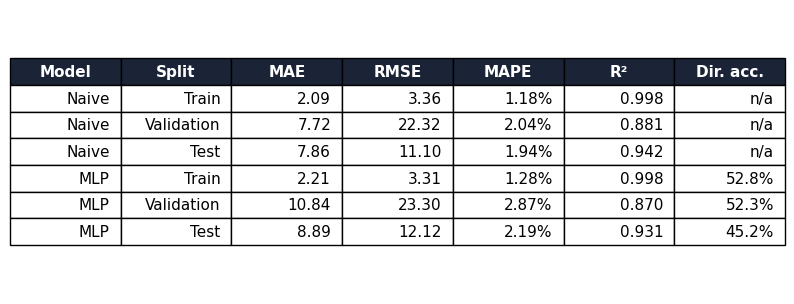

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 0.45 * len(fmt) + 1)); ax.axis("off")
t = ax.table(cellText=fmt.values, colLabels=fmt.columns, loc="center", cellLoc="right")
t.auto_set_font_size(False); t.set_fontsize(11); t.scale(1, 1.6)
for j in range(len(fmt.columns)):
    t[0, j].set_facecolor("#1b2336"); t[0, j].set_text_props(color="white", weight="bold")
plt.savefig("price_results_table.png", dpi=200, bbox_inches="tight")
plt.show()

# Walk-forward and Horizon Testing

## Cell A: Setup

In [14]:
H_LIST = [1, 5, 10]
STEP = 20                       # refit every 20 trading days

# full price series (df lost its last row to the shift(-1) dropna)
px_close = np.append(df.CLOSE.values, df.next_close.iloc[-1])
px_date  = pd.DatetimeIndex(list(df.DATE) + [df.tdate.iloc[-1]])
F = df[feats].values
test_start = int(np.argmax(np.asarray(px_date[1:] > pd.Timestamp("2025-10-10"))))
print("h=1 test samples:", len(df) - test_start)     # should be 177

def build(kind):
    if kind == "MLP":
        return Sequential([layers.Input((W*len(feats),)), layers.Dense(64, activation="relu"),
                           layers.Dropout(0.2), layers.Dense(32, activation="relu"), layers.Dense(1)])
    return Sequential([layers.Input((W, len(feats))), layers.LSTM(64), layers.Dropout(0.2),
                       layers.Dense(32, activation="relu"), layers.Dense(1)])

h=1 test samples: 177


## Cell B: Walk-forward function

In [15]:
def walk_forward(h, kind):
    idx = np.arange(W-1, len(df)-h+1)                      # origins with a known h-day target
    X = np.stack([F[i-W+1:i+1] for i in idx])
    y = np.log(px_close[idx+h] / px_close[idx])
    pred = np.full(len(idx), np.nan)
    first = int(np.where(idx >= test_start)[0][0])
    flat = (lambda a: a.reshape(len(a), -1)) if kind == "MLP" else (lambda a: a)

    for s in range(first, len(idx), STEP):
        e = min(s + STEP, len(idx))
        tr_pos = np.where(idx + h <= idx[s])[0]            # targets already known at fold start
        n_val = int(len(tr_pos) * 0.15)
        fit_pos, val_pos = tr_pos[:-(n_val + h)], tr_pos[-n_val:]   # h-day gap before validation

        sx = StandardScaler().fit(X[fit_pos].reshape(-1, len(feats)))
        sy = StandardScaler().fit(y[fit_pos].reshape(-1, 1))
        prep = lambda p: sx.transform(X[p].reshape(-1, len(feats))).reshape(len(p), W, len(feats))

        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(42)
        m = build(kind); m.compile("adam", "mse")
        m.fit(flat(prep(fit_pos)), sy.transform(y[fit_pos].reshape(-1, 1)),
              validation_data=(flat(prep(val_pos)), sy.transform(y[val_pos].reshape(-1, 1))),
              epochs=60, batch_size=32, verbose=0,
              callbacks=[callbacks.EarlyStopping(patience=10, restore_best_weights=True)])
        blk = np.arange(s, e)
        pred[blk] = sy.inverse_transform(m.predict(flat(prep(blk)), verbose=0)).ravel()

    ok = ~np.isnan(pred)
    prev = px_close[idx[ok]]
    return px_close[idx[ok]+h], prev * np.exp(pred[ok]), prev, px_date[idx[ok]+h]

## Cell C: Metrics, DM test and run

In [16]:
from scipy import stats

def metrics(a, p, prev):
    return {"MAE": MAE(a, p), "RMSE": np.sqrt(MSE(a, p)),
            "MAPE": np.mean(np.abs((a-p)/a))*100, "R²": r2_score(a, p),
            "Dir. acc.": np.mean(np.sign(a-prev) == np.sign(p-prev))*100}

def dm_hac(a, p_model, p_naive, h):
    d = np.abs(a - p_naive) - np.abs(a - p_model)          # >0 means model better
    n, dbar = len(d), d.mean()
    g = lambda k: np.mean((d[k:] - dbar) * (d[:n-k] - dbar))
    lrv = g(0) + 2 * sum((1 - k/h) * g(k) for k in range(1, h))
    t = dbar / np.sqrt(max(lrv, 1e-12) / n)
    return 1 - stats.norm.cdf(t)                           # one-sided p (H1: model better)

rows, store = [], {}
for h in H_LIST:
    for kind in ["MLP", "LSTM"]:
        a, p, prev, dts = walk_forward(h, kind)
        store[(h, kind)] = (a, p, prev, dts)
        if kind == "MLP":
            nm = metrics(a, prev, prev); nm["Dir. acc."] = np.nan
            rows.append({"Horizon": h, "Model": "Naive", **nm, "DM p": np.nan})
        rows.append({"Horizon": h, "Model": kind, **metrics(a, p, prev), "DM p": dm_hac(a, p, prev, h)})
        print(f"done h={h} {kind}")

res = pd.DataFrame(rows)
res.to_csv("walk_forward_multi_horizon.csv", index=False)
res.round(3)

done h=1 MLP
done h=1 LSTM
done h=5 MLP
done h=5 LSTM
done h=10 MLP
done h=10 LSTM


,Horizon,Model,MAE,RMSE,MAPE,R²,Dir. acc.,DM p
0,1,Naive,7.859,11.103,1.944,0.942,NaN,NaN
1,1,MLP,8.651,12.272,2.146,0.929,54.802,0.998
2,1,LSTM,8.214,11.579,2.038,0.937,53.672,0.960
3,5,Naive,19.218,25.889,4.704,0.691,NaN,NaN
4,5,MLP,21.751,30.018,5.370,0.584,49.711,0.986
5,5,LSTM,22.480,30.013,5.554,0.584,47.977,0.978
6,10,Naive,26.804,37.340,6.552,0.371,NaN,NaN
7,10,MLP,36.438,47.091,9.051,-0.000,49.405,1.000
8,10,LSTM,32.453,42.598,7.807,0.181,55.357,0.947


## Cell D: Optional plot for the slide

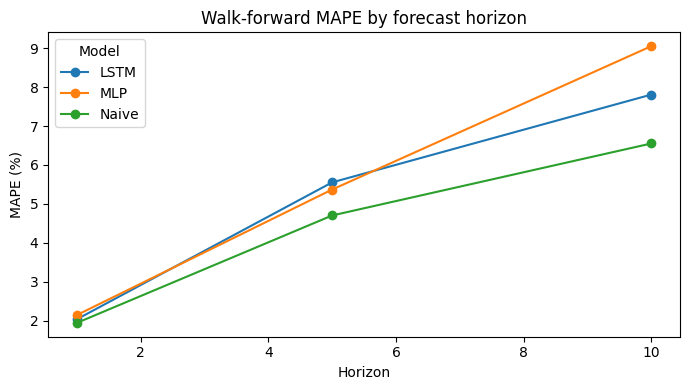

In [17]:
import matplotlib.pyplot as plt
res.pivot(index="Horizon", columns="Model", values="MAPE").plot(marker="o", figsize=(7,4))
plt.ylabel("MAPE (%)"); plt.title("Walk-forward MAPE by forecast horizon")
plt.tight_layout(); plt.savefig("walkforward_mape.png", dpi=200); plt.show()